# Regression Modelling of the Healthy Power Curve

Compares Random Forest and XGBoost (and simple baselines) for predicting expected power during normal operation, analyses the errors of the selected model, and predicts expected power for every record.

**Input:** `out/02_clustering/wind_features_clustered.csv` · **Outputs:** `out/03_regression/` and `figures/fig6-1_*`, `fig6-3_*`, `fig6-4_*`.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict, cross_validate
from xgboost import XGBRegressor

IN_PATH = Path("../out/02_clustering/wind_features_clustered.csv")
OUT_DIR = Path("../out/03_regression")
FIG_DIR = Path("../figures")
OUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
NORMAL_CLUSTER = 0
RATED_KW = 3600
MODEL_FEATURES = ["wind_speed", "wd_sin", "wd_cos"]
TARGET = "power_kw"
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

COLOR_MAIN, COLOR_ALT, COLOR_MUTED = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

features = pd.read_csv(IN_PATH)
print(features.shape)
print(features["cluster_state"].value_counts())

(50530, 23)
cluster_state
0                        40476
below_operating_range     9895
dbscan_noise                99
1                           42
2                           10
3                            8
Name: count, dtype: int64


## 1. Training data

Only the DBSCAN normal-operation cluster is used for training. Predictors are `wind_speed`, `wd_sin` and `wd_cos`; the target is `power_kw`. The theoretical power curve is a reference, not an input, and month is used only to define the validation folds.

In [2]:
normal_data = features[features["cluster"] == NORMAL_CLUSTER]
X = normal_data[MODEL_FEATURES]
y = normal_data[TARGET]
groups = normal_data["month"]
logo = LeaveOneGroupOut()

fold_sizes = groups.value_counts()
print("Normal-operation records:", len(normal_data))
print(f"Test folds: {fold_sizes.min():,} to {fold_sizes.max():,} records "
      f"(training on {len(normal_data) - fold_sizes.max():,} to {len(normal_data) - fold_sizes.min():,})")

Normal-operation records: 40476
Test folds: 2,769 to 4,235 records (training on 36,241 to 37,707)


## 2. Models and leave-one-month-out cross-validation

Each fold holds out one month and trains on the other eleven, so near-identical neighbouring records never sit on both sides of the split. Scores are the mean of the 12 folds.

In [3]:
def make_xgboost():
    return XGBRegressor(n_estimators=500, max_depth=6, learning_rate=0.05, subsample=0.8,
                        colsample_bytree=0.8, objective="reg:squarederror",
                        random_state=RANDOM_STATE, n_jobs=-1)


models = {
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                           random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": make_xgboost(),
}
SCORING = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}

rows = []
for name, model in models.items():
    start = time.perf_counter()
    scores = cross_validate(model, X, y, groups=groups, cv=logo, scoring=SCORING, n_jobs=-1)
    rows.append({"model": name,
                 "MAE_kW": -scores["test_mae"].mean(),
                 "RMSE_kW": -scores["test_rmse"].mean(),
                 "R2": scores["test_r2"].mean(),
                 "training_time_seconds": time.perf_counter() - start})
regression_results = pd.DataFrame(rows).sort_values(["RMSE_kW", "MAE_kW"], ignore_index=True)
best_model_name = regression_results.loc[0, "model"]
print("Best model:", best_model_name)
regression_results

Best model: XGBoost


,model,MAE_kW,RMSE_kW,R2,training_time_seconds
0,XGBoost,202.331532,388.660891,0.881679,5.891553
1,Random Forest,207.490066,401.610627,0.875365,55.099371


## 3. Baselines on the same folds

Simple references show whether the models add accuracy: the training-mean prediction, the manufacturer curve (no training), a 0.5 m/s binned power curve (mean power per wind-speed bin in the training months), and XGBoost with wind speed as its only input.

In [4]:
def binned_curve(train):
    """Mean power per 0.5 m/s wind-speed bin, interpolated across unseen bins."""
    curve = train.groupby("ws_bin")[TARGET].mean()
    return lambda data: np.interp(data["ws_bin"], curve.index, curve.to_numpy())


def predict_wind_speed_only(train, test):
    return make_xgboost().fit(train[["wind_speed"]], train[TARGET]).predict(test[["wind_speed"]])


baselines = {
    "Training-mean baseline": lambda train, test: np.full(len(test), train[TARGET].mean()),
    "Manufacturer curve (no training)": lambda train, test: test["theo_power_kw"].to_numpy(),
    "Binned power curve (0.5 m/s)": lambda train, test: binned_curve(train)(test),
    "XGBoost, wind speed only (check)": predict_wind_speed_only,
}

rows = []
for name, predict in baselines.items():
    fold_scores = []
    for train_idx, test_idx in logo.split(X, y, groups):
        test = normal_data.iloc[test_idx]
        pred = predict(normal_data.iloc[train_idx], test)
        fold_scores.append((mean_absolute_error(test[TARGET], pred),
                            root_mean_squared_error(test[TARGET], pred),
                            r2_score(test[TARGET], pred)))
    rows.append({"model": name, **dict(zip(["MAE_kW", "RMSE_kW", "R2"], np.mean(fold_scores, axis=0)))})

regression_comparison = pd.concat([regression_results, pd.DataFrame(rows)], ignore_index=True)
regression_comparison

,model,MAE_kW,RMSE_kW,R2,training_time_seconds
0,XGBoost,202.331532,388.660891,0.881679,5.891553
1,Random Forest,207.490066,401.610627,0.875365,55.099371
2,Training-mean baseline,1150.786899,1281.667171,-0.291086,NaN
3,Manufacturer curve (no training),235.779481,430.996882,0.848707,NaN
4,Binned power curve (0.5 m/s),194.417507,350.100421,0.897588,NaN
5,"XGBoost, wind speed only (check)",188.618233,346.229067,0.899036,NaN


## 4. Out-of-fold error analysis of the selected model

For every training record, the prediction made while its own month was held out is kept. Residual = actual − predicted, so a negative residual means the model expected more than the turbine delivered.

In [5]:
oof = normal_data[["month", "month_name", "wind_speed", "rule_state", TARGET]].copy()
oof["predicted_kw"] = cross_val_predict(models[best_model_name], X, y, groups=groups, cv=logo, n_jobs=-1)
oof["residual_kw"] = oof[TARGET] - oof["predicted_kw"]


def error_table(data, by):
    table = data.groupby(by, observed=True).apply(lambda d: pd.Series({
        "records": len(d),
        "MAE_kW": d["residual_kw"].abs().mean(),
        "RMSE_kW": np.sqrt((d["residual_kw"] ** 2).mean()),
        "mean_residual_kW": d["residual_kw"].mean(),
        "median_residual_kW": d["residual_kw"].median(),
    }), include_groups=False)
    return table.astype({"records": int})


def r2_of(data):
    return r2_score(data[TARGET], data["predicted_kw"])


error_by_month = error_table(oof, "month_name").reindex(MONTHS)
error_by_month["R2"] = oof.groupby("month_name").apply(r2_of, include_groups=False)
print(f"Fold-average MAE: {error_by_month['MAE_kW'].mean():.1f} kW "
      f"(std {error_by_month['MAE_kW'].std():.0f} kW) | overall median residual: "
      f"{oof['residual_kw'].median():+.0f} kW")
error_by_month.round(2)

Fold-average MAE: 202.3 kW (std 129 kW) | overall median residual: +31 kW


,records,MAE_kW,RMSE_kW,mean_residual_kW,median_residual_kW,R2
month_name,,,,,,
Jan,3127,533.08,990.43,-361.75,21.92,0.52
Feb,3266,294.17,584.84,-50.24,60.95,0.82
Mar,3859,179.50,386.73,75.57,43.52,0.92
Apr,2769,144.97,365.11,-8.13,7.55,0.92
May,3261,146.10,255.50,70.87,25.37,0.93
Jun,3150,94.40,165.54,17.55,5.81,0.98
Jul,3028,74.32,127.41,6.67,-3.12,0.96
Aug,4235,142.42,300.29,20.92,9.36,0.93
Sep,3306,116.67,210.81,70.16,29.46,0.97


In [6]:
error_by_state = error_table(oof, "rule_state")
print(f"R² on near_curve records only: {r2_of(oof[oof['rule_state'] == 'near_curve']):.3f}")
error_by_state.round(2)

R² on near_curve records only: 0.957


,records,MAE_kW,RMSE_kW,mean_residual_kW,median_residual_kW
rule_state,,,,,
near_curve,31191,145.98,250.49,111.71,59.53
underperforming,7066,176.81,411.40,-152.06,-35.43
zero_output,2219,1056.40,1491.98,-1052.23,-644.80


In [7]:
WIND_BANDS = [3.5, 5, 7, 9, 11, 13, 15, np.inf]
BAND_LABELS = ["3.5–5", "5–7", "7–9", "9–11", "11–13", "13–15", "≥15"]
oof["wind_band"] = pd.cut(oof["wind_speed"], WIND_BANDS, right=False, labels=BAND_LABELS)
error_by_wind_band = error_table(oof, "wind_band")
error_by_wind_band.round(2)

,records,MAE_kW,RMSE_kW,mean_residual_kW,median_residual_kW
wind_band,,,,,
3.5–5,5849,51.26,75.70,-1.42,2.47
5–7,9021,102.61,173.18,2.52,22.90
7–9,8705,230.60,401.94,1.81,58.11
9–11,6633,402.86,696.80,-0.83,100.04
11–13,4925,250.76,554.02,0.45,53.54
13–15,2614,247.93,686.53,-7.81,27.67
≥15,2729,131.46,391.30,25.14,35.53


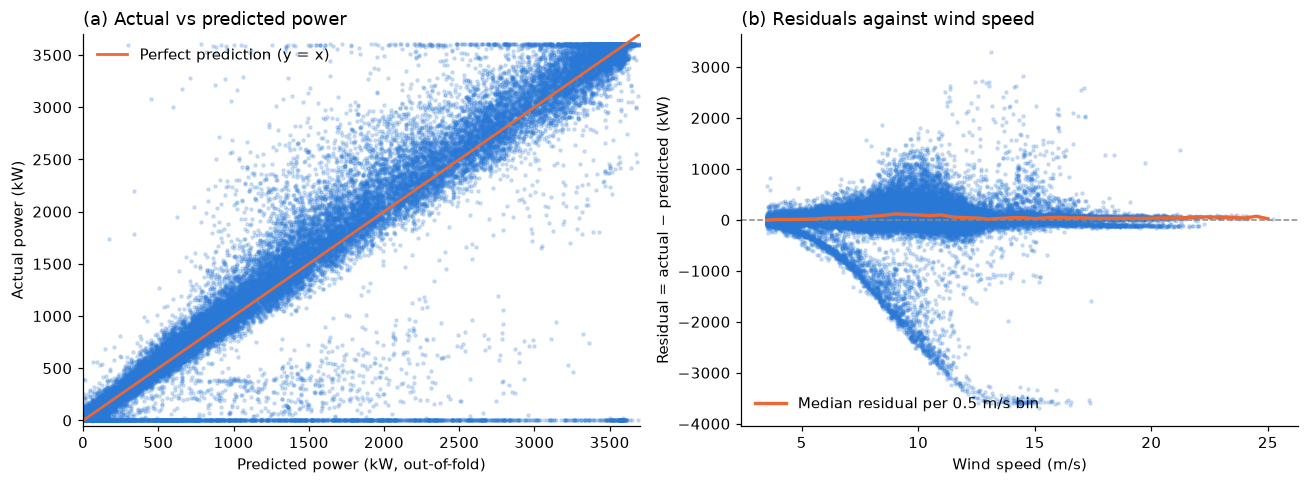

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
ax.scatter(oof["predicted_kw"], oof[TARGET], s=4, alpha=0.2, color=COLOR_MAIN, rasterized=True)
ax.plot([0, 3700], [0, 3700], color=COLOR_ALT, lw=1.8, label="Perfect prediction (y = x)")
ax.set(xlim=(0, 3700), ylim=(-50, 3700), xlabel="Predicted power (kW, out-of-fold)", ylabel="Actual power (kW)")
ax.set_title("(a) Actual vs predicted power", loc="left")
ax.legend(frameon=False, loc="upper left")

ax = axes[1]
median_by_bin = oof.groupby((oof["wind_speed"] // 0.5) * 0.5)["residual_kw"].median()
ax.scatter(oof["wind_speed"], oof["residual_kw"], s=4, alpha=0.2, color=COLOR_MAIN, rasterized=True)
ax.axhline(0, color=COLOR_MUTED, lw=1, ls="--")
ax.plot(median_by_bin.index, median_by_bin, color=COLOR_ALT, lw=2.2, label="Median residual per 0.5 m/s bin")
ax.set(xlabel="Wind speed (m/s)", ylabel="Residual = actual − predicted (kW)")
ax.set_title("(b) Residuals against wind speed", loc="left")
ax.legend(frameon=False, loc="lower left")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig6-1_actual_vs_predicted.png")
plt.show()

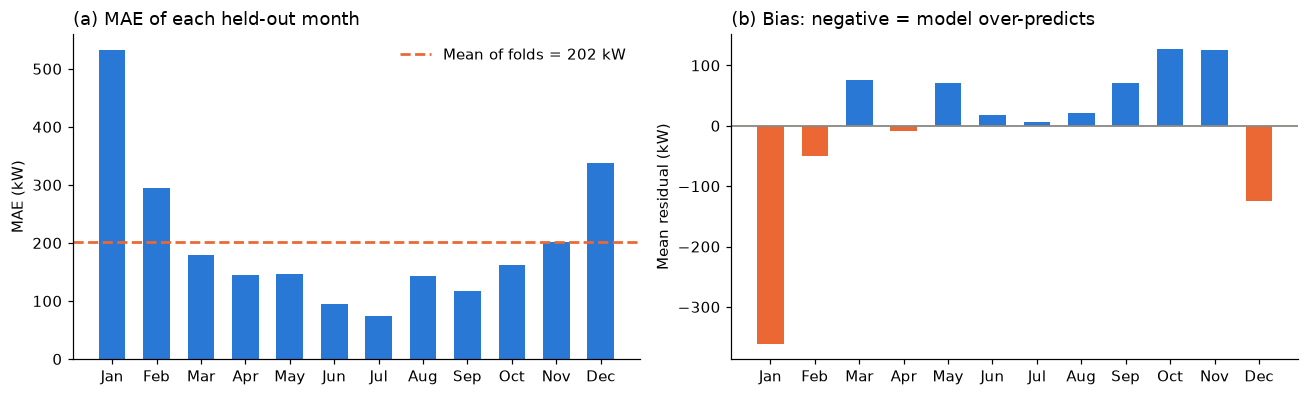

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.7))
ax = axes[0]
ax.bar(MONTHS, error_by_month["MAE_kW"], color=COLOR_MAIN, width=0.6)
ax.axhline(error_by_month["MAE_kW"].mean(), color=COLOR_ALT, lw=1.8, ls="--",
           label=f"Mean of folds = {error_by_month['MAE_kW'].mean():.0f} kW")
ax.set_ylabel("MAE (kW)")
ax.set_title("(a) MAE of each held-out month", loc="left")
ax.legend(frameon=False)

ax = axes[1]
bias = error_by_month["mean_residual_kW"]
ax.bar(MONTHS, bias, color=np.where(bias < 0, COLOR_ALT, COLOR_MAIN), width=0.6)
ax.axhline(0, color=COLOR_MUTED, lw=1.2)
ax.set_ylabel("Mean residual (kW)")
ax.set_title("(b) Bias: negative = model over-predicts", loc="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig6-3_error_by_month.png")
plt.show()

## 5. Final model and expected power for all records

The selected model is retrained on all normal-operation records and predicts expected power for all 50,530 records, clipped to 0–3,600 kW. A binned power curve fitted on the same records is saved as well, so notebook 04 can check how sensitive the loss estimate is to the choice of healthy curve.

In [10]:
best_model = models[best_model_name].fit(X, y)

features["predicted_power_kw"] = np.clip(best_model.predict(features[MODEL_FEATURES]), 0, RATED_KW)
features["binned_power_kw"] = binned_curve(normal_data)(features)
features["ml_shortfall_kwh"] = (features["predicted_power_kw"] - features[TARGET]).clip(lower=0) / 6

## 6. Explainability

Permutation importance (on a 10,000-record sample of the training cluster) measures how much the MAE rises when one input is shuffled. The direction profile holds wind speed fixed and varies only the wind direction, one prediction per 30° sector centre.

In [11]:
sample = normal_data.sample(n=10_000, random_state=RANDOM_STATE)
permutation = permutation_importance(best_model, sample[MODEL_FEATURES], sample[TARGET],
                                     scoring="neg_mean_absolute_error", n_repeats=10,
                                     random_state=RANDOM_STATE)
importance = pd.DataFrame({"mae_increase_kW": permutation.importances_mean,
                           "model_importance_share": best_model.feature_importances_},
                          index=MODEL_FEATURES)
importance

,mae_increase_kW,model_importance_share
wind_speed,1228.161762,0.918881
wd_sin,58.808080,0.027442
wd_cos,60.866483,0.053677


In [12]:
sector_centres = np.arange(15, 360, 30)
direction_profile = pd.DataFrame(index=pd.Index(sector_centres, name="wind_dir_deg"))
for wind_speed in (6, 9):
    grid = pd.DataFrame({"wind_speed": wind_speed,
                         "wd_sin": np.sin(np.deg2rad(sector_centres)),
                         "wd_cos": np.cos(np.deg2rad(sector_centres))})
    direction_profile[f"predicted_kw_at_{wind_speed}ms"] = best_model.predict(grid[MODEL_FEATURES])
print((direction_profile.max() - direction_profile.min()).round(0).rename("spread_kW"))
direction_profile.round(0)

predicted_kw_at_6ms    130.0
predicted_kw_at_9ms    627.0
Name: spread_kW, dtype: float32


,predicted_kw_at_6ms,predicted_kw_at_9ms
wind_dir_deg,,
15,581.0,1350.0
45,547.0,1751.0
75,513.0,1619.0
105,615.0,1567.0
135,532.0,1667.0
165,552.0,1812.0
195,543.0,1924.0
225,514.0,1778.0
255,552.0,1797.0


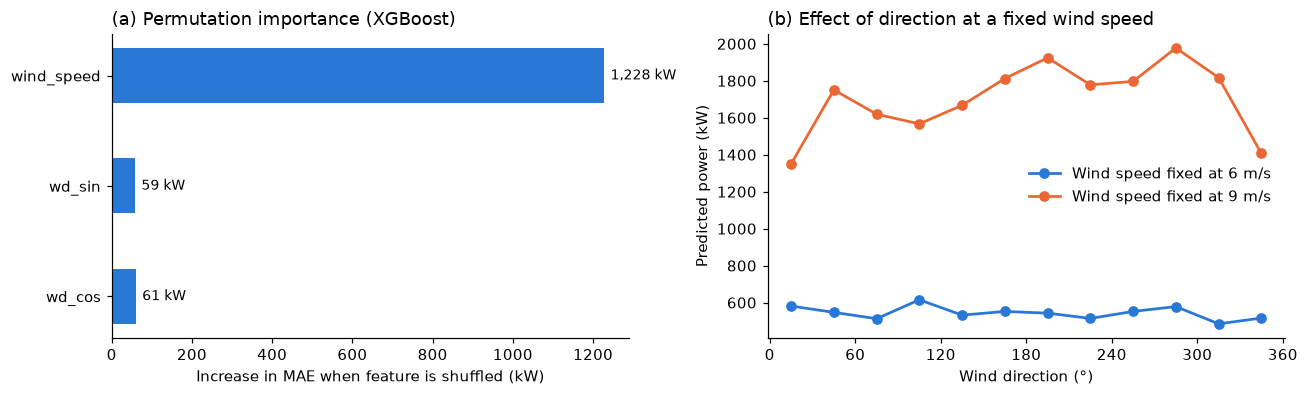

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.7))
ax = axes[0]
bars = ax.barh(importance.index, importance["mae_increase_kW"], color=COLOR_MAIN, height=0.5)
ax.bar_label(bars, labels=[f"{v:,.0f} kW" for v in importance["mae_increase_kW"]], padding=4, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Increase in MAE when feature is shuffled (kW)")
ax.set_title(f"(a) Permutation importance ({best_model_name})", loc="left")

ax = axes[1]
for column, color in zip(direction_profile.columns, (COLOR_MAIN, COLOR_ALT)):
    speed = column.removeprefix("predicted_kw_at_").removesuffix("ms")
    ax.plot(direction_profile.index, direction_profile[column], color=color, marker="o", lw=1.8,
            label=f"Wind speed fixed at {speed} m/s")
ax.set_xticks(range(0, 361, 60))
ax.set(xlabel="Wind direction (°)", ylabel="Predicted power (kW)")
ax.set_title("(b) Effect of direction at a fixed wind speed", loc="left")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig6-4_explainability.png")
plt.show()

In [14]:
features.to_csv(OUT_DIR / "model_results.csv", index=False)
regression_comparison.to_csv(OUT_DIR / "regression_comparison.csv", index=False)
error_by_month.to_csv(OUT_DIR / "error_by_month.csv")
error_by_state.to_csv(OUT_DIR / "error_by_state.csv")
error_by_wind_band.to_csv(OUT_DIR / "error_by_wind_band.csv")
importance.to_csv(OUT_DIR / "feature_importance.csv", index_label="feature")
direction_profile.to_csv(OUT_DIR / "direction_profile.csv")
print("Saved:", *sorted(p.name for p in OUT_DIR.iterdir()), sep="\n  ")

Saved:
  direction_profile.csv
  error_by_month.csv
  error_by_state.csv
  error_by_wind_band.csv
  feature_importance.csv
  model_results.csv
  regression_comparison.csv


## Summary

- XGBoost is the better of the two models under leave-one-month-out validation and is used for the loss analysis in notebook 04.
- A 0.5 m/s binned power curve and XGBoost with wind speed alone are slightly more accurate, so the direction inputs do not help on unseen months.
- Errors are largest on the stops and low-output records left inside the training cluster, and in the winter months where those stops happened.
- `model_results.csv` holds the expected power for every record. The model is not trained below 3.5 m/s; notebook 04 uses the manufacturer curve there.